In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [2]:
df = pd.read_csv("../Data/Cleaned/Plant_1_Feature_Engineered.csv")

df.head()


,PLANT_ID,SOURCE_KEY_x,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_y,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,HOUR,DAY,MONTH,WEEKDAY,IS_WEEKEND
0,4135001,0,0.0,0.0,0.0,6259559.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,0,15,5,4,0
1,4135001,1,0.0,0.0,0.0,6183645.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,0,15,5,4,0
2,4135001,2,0.0,0.0,0.0,6987759.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,0,15,5,4,0
3,4135001,3,0.0,0.0,0.0,7602960.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,0,15,5,4,0
4,4135001,4,0.0,0.0,0.0,7158964.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,0,15,5,4,0


In [3]:
X = df.drop(columns=["AC_POWER","SOURCE_KEY_y","DC_POWER","DAILY_YIELD","TOTAL_YIELD","PLANT_ID"])

y = df["AC_POWER"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=14
)


In [4]:
lr = LinearRegression()

lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)

mae_lr = mean_absolute_error(y_test, pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, pred_lr))
r2_lr = r2_score(y_test, pred_lr)

print("MAE :", mae_lr)

print("RMSE :", rmse_lr)

print("R2 :", r2_lr)


MAE : 26.412824783669063
RMSE : 58.52947461753551
R2 : 0.978138869408736


In [5]:
dt = DecisionTreeRegressor(random_state=14)

dt.fit(X_train, y_train)

pred_dt = dt.predict(X_test)

mae_dt = mean_absolute_error(y_test, pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, pred_dt))
r2_dt = r2_score(y_test, pred_dt)

print("MAE :", mae_dt)

print("RMSE :", rmse_dt)

print("R2 :", r2_dt)


MAE : 18.716876201877064
RMSE : 56.16338124462671
R2 : 0.9798706449958757


In [6]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=14
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)

mae_rf = mean_absolute_error(y_test, pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
r2_rf = r2_score(y_test, pred_rf)

print("MAE :", mae_rf)

print("RMSE :", rmse_rf)

print("R2 :", r2_rf)


MAE : 15.162258534441467
RMSE : 47.5860036835799
R2 : 0.9855495345865107


In [7]:
gb = GradientBoostingRegressor(random_state=14)

gb.fit(X_train, y_train)

pred_gb = gb.predict(X_test)

mae_gb = mean_absolute_error(y_test, pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, pred_gb))
r2_gb = r2_score(y_test, pred_gb)

print("MAE :", mae_gb)

print("RMSE :", rmse_gb)

print("R2 :", r2_gb)


MAE : 18.337600370749886
RMSE : 49.83591586071685
R2 : 0.9841507668201444


In [8]:
xgb = XGBRegressor(
    n_estimators=100,
    random_state=14
)

xgb.fit(X_train, y_train)

pred_xgb = xgb.predict(X_test)

mae_xgb = mean_absolute_error(y_test, pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, pred_xgb))
r2_xgb = r2_score(y_test, pred_xgb)

print("MAE :", mae_xgb)

print("RMSE :", rmse_xgb)

print("R2 :", r2_xgb)


MAE : 14.70041769607756
RMSE : 40.49042825035609
R2 : 0.989537677393752


In [9]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting", "XGBoost"],
    "MAE": [mae_lr, mae_dt, mae_rf, mae_gb, mae_xgb],
    "RMSE": [rmse_lr, rmse_dt, rmse_rf, rmse_gb, rmse_xgb],
    "R2 Score": [r2_lr, r2_dt, r2_rf, r2_gb, r2_xgb]
})

results


,Model,MAE,RMSE,R2 Score
0,Linear Regression,26.412825,58.529475,0.978139
1,Decision Tree,18.716876,56.163381,0.979871
2,Random Forest,15.162259,47.586004,0.985550
3,Gradient Boosting,18.337600,49.835916,0.984151
4,XGBoost,14.700418,40.490428,0.989538


In [10]:
importance_rf = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

importance_xgb = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb.feature_importances_
}).sort_values(by="Importance", ascending=False)

importance_rf


,Feature,Importance
3,IRRADIATION,0.984935
0,SOURCE_KEY_x,0.007463
2,MODULE_TEMPERATURE,0.002099
1,AMBIENT_TEMPERATURE,0.001657
5,DAY,0.001274
4,HOUR,0.001176
7,WEEKDAY,0.000963
6,MONTH,0.000282
8,IS_WEEKEND,0.000150


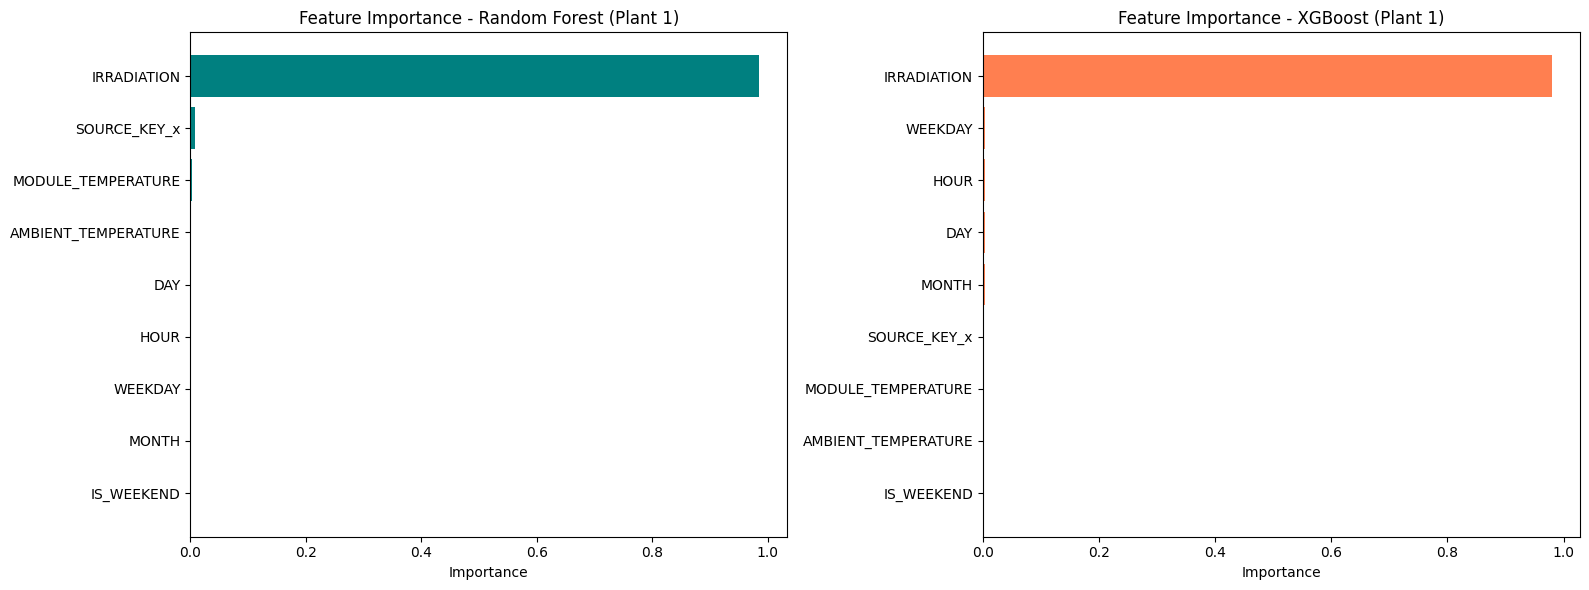

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(importance_rf["Feature"], importance_rf["Importance"], color="teal")
axes[0].set_title("Feature Importance - Random Forest (Plant 1)")
axes[0].set_xlabel("Importance")
axes[0].invert_yaxis()

axes[1].barh(importance_xgb["Feature"], importance_xgb["Importance"], color="coral")
axes[1].set_title("Feature Importance - XGBoost (Plant 1)")
axes[1].set_xlabel("Importance")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


# Machine Learning Model Evaluation & Analysis (Plant 1)

Five regression algorithms were trained and evaluated for **Plant 1**:
1. **Linear Regression**
2. **Decision Tree Regressor**
3. **Random Forest Regressor**
4. **Gradient Boosting Regressor**
5. **XGBoost Regressor**

## Observations

- **XGBoost achieved the highest performance** on Plant 1, reaching an $R^2$ score of **0.9895** and reducing the Root Mean Squared Error down to **40.49 kW** (MAE of **14.70 kW**).
- **Random Forest** achieved the second-highest score ($R^2$ of **0.9856**, RMSE of **47.59 kW**).
- **Gradient Boosting** achieved solid performance with an $R^2$ of **0.9842** and RMSE of **49.84 kW**.
- Both ensemble boosting and bagging methods substantially outperform the baseline Linear Regression model ($R^2$ **0.9781**).

## Feature Importance

- Both Random Forest and XGBoost confirm that **Solar Irradiation is by far the primary predictive feature**, accounting for ~98.5% of model importance in Plant 1.
- Inverter identifier (`SOURCE_KEY_x`), module temperature, ambient temperature, and temporal indicators contribute marginal fine-tuning adjustments.

## Conclusion

Tree-based boosting (XGBoost) and bagging (Random Forest) effectively capture non-linear photovoltaic dynamics and temperature derating. For Plant 1, **XGBoost Regressor** demonstrates state-of-the-art predictive accuracy with the lowest overall error metrics.
